# Implementation and Evaluation of a NetFlow Behavioral Anomaly Detection Prototype

**CSC 786: Computer Science Problems**

**Student:** Carlos Ocasio  
**Professor:** Dr. Abid Mehmood  
**Experiment:** Six Hour NetFlow Laboratory Experiment

## Project Overview

This notebook documents the implementation and evaluation of a NetFlow behavioral anomaly detection prototype using Isolation Forest.

The experiment uses NetFlow traffic collected from a six hour laboratory environment. Traffic records are processed into 1, 5, and 10 minute aggregation windows, and 12 traffic features are extracted for anomaly detection.

The objective is to evaluate how temporal aggregation affects Isolation Forest performance and examine the tradeoffs associated with different anomaly detection thresholds.

Model performance is evaluated using precision, recall, F1 score, false positive rate, and ROC AUC.

The notebook is intended to support reproducibility by allowing others to execute the analysis using the provided datasets and Python scripts.

In [1]:
!git clone https://github.com/carlosocasio/csc786-netflow-anomaly-detection.git

Cloning into 'csc786-netflow-anomaly-detection'...
remote: Enumerating objects: 74, done.
remote: Counting objects: 100% (74/74), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 74 (delta 17), reused 43 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (74/74), 3.35 MiB | 5.91 MiB/s, done.
Resolving deltas: 100% (17/17), done.


In [2]:
from pathlib import Path

BASE = Path("/content/csc786-netflow-anomaly-detection")
DATA = BASE / "data" / "lab_6h"
RESULTS = BASE / "results" / "lab_6h"

print("Repository exists:", BASE.exists())
print("Data directory exists:", DATA.exists())

Repository exists: True
Data directory exists: True


In [3]:
import pandas as pd

print("Raw NetFlow:", (DATA / "netflow_6h_raw.csv").exists())
print("Experiment log:", list(DATA.glob("experiment_*.csv")))

for minutes in [1, 5, 10]:
    file = DATA / f"netflow_features_{minutes}min.csv"
    df = pd.read_csv(file)

    print(f"{minutes} minute windows: {len(df)}")

Raw NetFlow: True
Experiment log: [PosixPath('/content/csc786-netflow-anomaly-detection/data/lab_6h/experiment_20261108T055029Z.csv')]
1 minute windows: 360
5 minute windows: 72
10 minute windows: 36


In [4]:
!python /content/csc786-netflow-anomaly-detection/scripts/analysis/isolation_forest_baseline.py


Isolation Forest: 1 minute aggregation
Training windows: 250
Normal training windows used: 217
Testing windows: 110
True anomalies: 12
Predicted anomalies: 17

Threshold: 0.5371
Precision: 0.588
Recall: 0.833
F1 score: 0.690
False positive rate: 0.071
ROC AUC: 0.914

Confusion Matrix
True negatives: 91
False positives: 7
False negatives: 2
True positives: 10

Saved predictions: /content/csc786-netflow-anomaly-detection/results/lab_6h/predictions_1min.csv

Isolation Forest: 5 minute aggregation
Training windows: 50
Normal training windows used: 24
Testing windows: 22
True anomalies: 10
Predicted anomalies: 11

Threshold: 0.5696
Precision: 0.909
Recall: 1.000
F1 score: 0.952
False positive rate: 0.083
ROC AUC: 0.975

Confusion Matrix
True negatives: 11
False positives: 1
False negatives: 0
True positives: 10

Saved predictions: /content/csc786-netflow-anomaly-detection/results/lab_6h/predictions_5min.csv

Isolation Forest: 10 minute aggregation
Training windows: 25
Normal training windo

In [5]:
baseline_results = pd.read_csv(RESULTS / "isolation_forest_comparison.csv")

baseline_results.round(3)

,aggregation_minutes,training_windows,normal_training_windows,testing_windows,true_anomalies,predicted_anomalies,threshold,precision,recall,f1_score,false_positive_rate,roc_auc,true_negatives,false_positives,false_negatives,true_positives
0,1,250,217,110,12,17,0.537,0.588,0.833,0.690,0.071,0.914,91,7,2,10
1,5,50,24,22,10,11,0.570,0.909,1.000,0.952,0.083,0.975,11,1,0,10
2,10,25,12,11,5,6,0.579,0.833,1.000,0.909,0.167,1.000,5,1,0,5


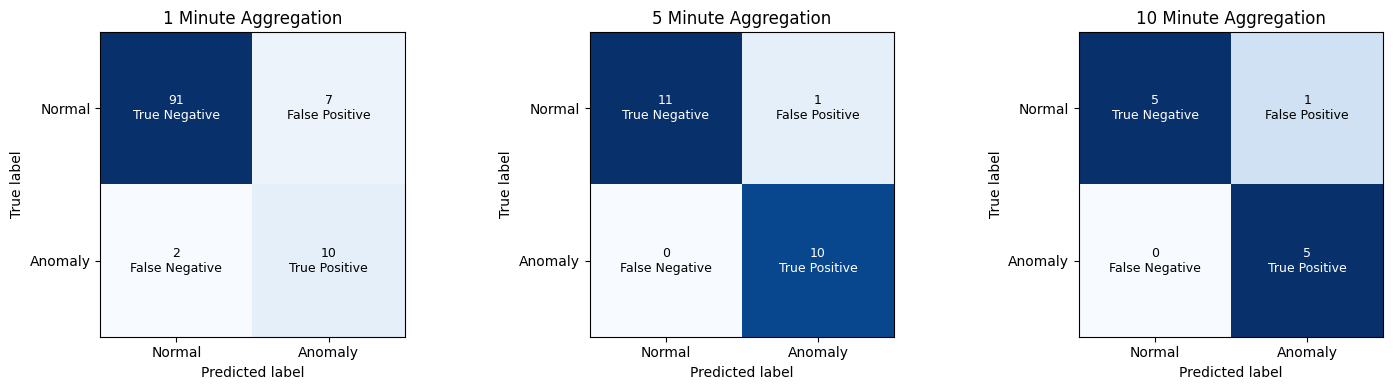

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cell_labels = [
    ["True Negative", "False Positive"],
    ["False Negative", "True Positive"]
]

for ax, minutes in zip(axes, [1, 5, 10]):
    predictions = pd.read_csv(RESULTS / f"predictions_{minutes}min.csv")

    matrix = confusion_matrix(
        predictions["label"],
        predictions["prediction"],
        labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Normal", "Anomaly"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        include_values=False
    )

    for row in range(2):
        for col in range(2):
            value = matrix[row, col]
            label = cell_labels[row][col]

            color = "white" if value > matrix.max() / 2 else "black"

            ax.text(
                col, row,
                f"{value}\n{label}",
                ha="center",
                va="center",
                fontsize=9,
                color=color
            )

    ax.set_title(f"{minutes} Minute Aggregation")

plt.tight_layout()
plt.show()

In [7]:
!python /content/csc786-netflow-anomaly-detection/scripts/analysis/isolation_forest_threshold.py


1 minute aggregation
Normal training windows: 217
Testing windows: 110
True anomalous windows: 12
Percentile 95: Threshold=0.5707 Alerts= 13 Precision=0.769 Recall=0.833 F1=0.800 FPR=0.031
Percentile 90: Threshold=0.5371 Alerts= 17 Precision=0.588 Recall=0.833 F1=0.690 FPR=0.071
Percentile 85: Threshold=0.5024 Alerts= 24 Precision=0.417 Recall=0.833 F1=0.556 FPR=0.143
Percentile 80: Threshold=0.4859 Alerts= 28 Precision=0.357 Recall=0.833 F1=0.500 FPR=0.184
Saved scores: /content/csc786-netflow-anomaly-detection/results/lab_6h/threshold_scores_1min.csv

5 minute aggregation
Normal training windows: 24
Testing windows: 22
True anomalous windows: 10
Percentile 95: Threshold=0.5730 Alerts= 11 Precision=0.909 Recall=1.000 F1=0.952 FPR=0.083
Percentile 90: Threshold=0.5696 Alerts= 11 Precision=0.909 Recall=1.000 F1=0.952 FPR=0.083
Percentile 85: Threshold=0.5555 Alerts= 11 Precision=0.909 Recall=1.000 F1=0.952 FPR=0.083
Percentile 80: Threshold=0.5407 Alerts= 12 Precision=0.833 Recall=1.00

In [8]:
threshold_results = pd.read_csv(RESULTS / "threshold_comparison.csv")

threshold_results.round(3)

,aggregation_minutes,percentile,threshold,training_windows,testing_windows,true_anomalies,alert_count,precision,recall,f1_score,false_positive_rate,roc_auc,true_negatives,false_positives,false_negatives,true_positives
0,1,95,0.571,217,110,12,13,0.769,0.833,0.800,0.031,0.914,95,3,2,10
1,1,90,0.537,217,110,12,17,0.588,0.833,0.690,0.071,0.914,91,7,2,10
2,1,85,0.502,217,110,12,24,0.417,0.833,0.556,0.143,0.914,84,14,2,10
3,1,80,0.486,217,110,12,28,0.357,0.833,0.500,0.184,0.914,80,18,2,10
4,5,95,0.573,24,22,10,11,0.909,1.000,0.952,0.083,0.975,11,1,0,10
5,5,90,0.570,24,22,10,11,0.909,1.000,0.952,0.083,0.975,11,1,0,10
6,5,85,0.555,24,22,10,11,0.909,1.000,0.952,0.083,0.975,11,1,0,10
7,5,80,0.541,24,22,10,12,0.833,1.000,0.909,0.167,0.975,10,2,0,10
8,10,95,0.592,12,11,5,5,1.000,1.000,1.000,0.000,1.000,6,0,0,5
9,10,90,0.579,12,11,5,6,0.833,1.000,0.909,0.167,1.000,5,1,0,5


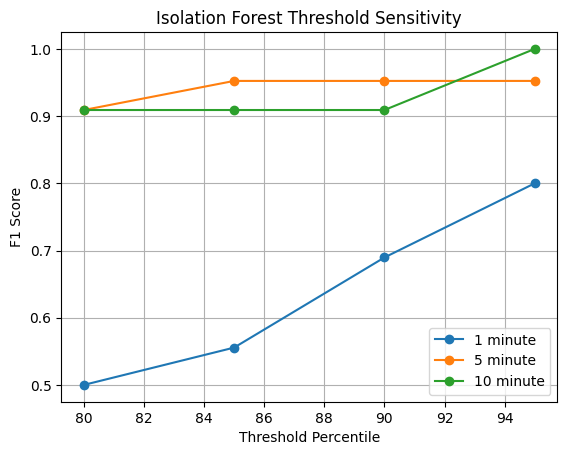

In [9]:
import matplotlib.pyplot as plt

for minutes in [1, 5, 10]:
    data = threshold_results[
        threshold_results["aggregation_minutes"] == minutes
    ]

    plt.plot(
        data["percentile"],
        data["f1_score"],
        marker="o",
        label=f"{minutes} minute"
    )

plt.xlabel("Threshold Percentile")
plt.ylabel("F1 Score")
plt.title("Isolation Forest Threshold Sensitivity")
plt.legend()
plt.grid(True)
plt.show()

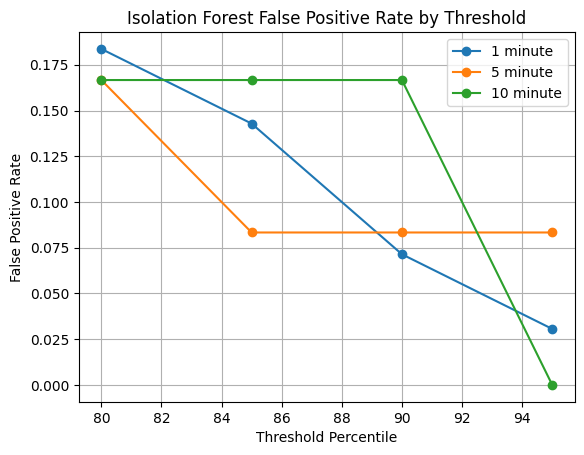

In [10]:
for minutes in [1, 5, 10]:
    data = threshold_results[
        threshold_results["aggregation_minutes"] == minutes
    ]

    plt.plot(
        data["percentile"],
        data["false_positive_rate"],
        marker="o",
        label=f"{minutes} minute"
    )

plt.xlabel("Threshold Percentile")
plt.ylabel("False Positive Rate")
plt.title("Isolation Forest False Positive Rate by Threshold")
plt.legend()
plt.grid(True)
plt.show()

**Results and Discussion**

---

The six hour laboratory experiment evaluated Isolation Forest using NetFlow features aggregated into 1, 5, and 10 minute intervals.

At the baseline 90th percentile threshold, the 5 minute aggregation achieved the highest F1 score of 0.952, compared with 0.690 for the 1 minute interval and 0.909 for the 10 minute interval.

The threshold sensitivity evaluation showed that increasing the threshold percentile generally reduced the number of alerts and false positives. For the 1 minute interval, increasing the threshold from the 80th to the 95th percentile reduced the false positive rate from 0.184 to 0.031 while maintaining a recall of 0.833.

The 5 minute interval produced consistent results across the 85th, 90th, and 95th percentiles. The 10 minute interval achieved an F1 score of 1.000 at the 95th percentile, although this result was based on only 11 testing windows.


**Limitations**

---

The laboratory experiment covered only six hours of network traffic. Longer aggregation intervals produced fewer observations, limiting the reliability of the evaluation metrics. The results also reflect traffic generated in a controlled laboratory environment rather than production network traffic.

Additional experiments using longer collection periods would help determine whether these findings generalize to larger datasets.